# Market, level 1: every formula by hand

The market's equations one at a time, each on numbers small enough to check on
paper. No network is loaded; only the core functions are called.

Every section has the same four parts:

1. **The rule**, as the phase card of the [full cycle](../../docs/methodology/market/step.md)
   states it (with the paper's equation).
2. **By hand**: the expected values, written from that rule in plain arithmetic.
   This cell is the expectation: read it against the rule, not against the code.
3. **The code**: the real core function on the same numbers.
4. **Side by side**: every quantity, with `yes` or `NO`.

Change any number and run the section again. The last cell lists every section
with PASS or FAIL.

The other levels: [level 2](market_2_step.ipynb) plays one step of the real
market phase by phase; [level 3](market_3_days.ipynb) checks rules over whole
days.

In [1]:
import math
import sys
from dataclasses import replace
from pathlib import Path
from types import SimpleNamespace

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "core" / "market").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from core.config.scenario import BatterySetup, DsoSetup, load_prices, price_at
from core.grid.contract import GridPath
from core.grid.graph import GraphGrid, capacities
from core.market.agent.battery import Battery
from core.market.agent.der import Participant
from core.market.clearing import Clearing, ClearingRules
from core.market.clearing_price import ClearingMechanism
from core.market.dso import DSO_ID, Dso
from core.market.order import Order, Trade
from core.market.reputation import ReputationHandler

pd.set_option("display.precision", 6)
pd.set_option("display.width", 160)

RESULTS = {}


def same(a, b, tol=1e-9) -> bool:
    # Numbers match within a tolerance (float rounding); anything else exactly.
    if isinstance(a, float) or isinstance(b, float):
        return a is not None and b is not None and math.isclose(a, b, abs_tol=tol)
    return a == b


def compare(section: str, hand: dict, code: dict) -> pd.DataFrame:
    # The hand values against the code's, one row per quantity; the section's
    # result goes into RESULTS for the summary at the end.
    rows = []
    for quantity in hand:
        match = same(hand[quantity], code[quantity])
        rows.append({
            "quantity": quantity,
            "by hand": hand[quantity],
            "code": code[quantity],
            "match": "yes" if match else "NO",
        })
    all_match = all(row["match"] == "yes" for row in rows)
    RESULTS[section] = "PASS" if all_match else "FAIL"
    return pd.DataFrame(rows).set_index("quantity")

## 1. Tariffs: time of use

**Rule** ([phase 1](../../docs/methodology/market/step.md#1-inputs), decision MP-0b). The
utility price follows `[start hour, price]` pairs, each price until the next
start: 0.20 before 07:00, 0.30 from 07:00, 0.40 from 17:00, 0.20 again from
22:00. Without a schedule the flat price holds all day. The feed-in tariff is
flat (0.08).

In [2]:
FLAT_UTILITY = 0.30
HOURS = [0, 6, 7, 16, 17, 21, 22, 23]   # both sides of every switch

# By hand: each hour's price read off the rule.
hand = {
    "flat, at 13:00": 0.30,        # no series: the flat price all day
    "time of use, 0:00": 0.20,     # before 07:00
    "time of use, 6:00": 0.20,
    "time of use, 7:00": 0.30,     # from 07:00
    "time of use, 16:00": 0.30,
    "time of use, 17:00": 0.40,    # from 17:00
    "time of use, 21:00": 0.40,
    "time of use, 22:00": 0.20,    # from 22:00
    "time of use, 23:00": 0.20,
}

# The code: price_at(series, hour); flat tariffs are a series of one price
code = {}
code["flat, at 13:00"] = price_at(load_prices({"utility": FLAT_UTILITY, "feed_in": 0.08}, 1.0)["utility"], 13)
for hour in HOURS:
    code[f"time of use, {hour}:00"] = price_at(load_prices("synthetic_day", 1.0)["utility"], hour)

compare("1 tariffs", hand, code)

,by hand,code,match
quantity,,,
"flat, at 13:00",0.3,0.3,yes
"time of use, 0:00",0.2,0.2,yes
"time of use, 6:00",0.2,0.2,yes
"time of use, 7:00",0.3,0.3,yes
"time of use, 16:00",0.3,0.3,yes
"time of use, 17:00",0.4,0.4,yes
"time of use, 21:00",0.4,0.4,yes
"time of use, 22:00",0.2,0.2,yes
"time of use, 23:00",0.2,0.2,yes


## 2. What a participant may order (eq. 15)

**Rule** ([phase 2](../../docs/methodology/market/step.md#2-orders), [P1] eq. 15a-d). The
battery holds $E$ within $[\text{SoC}_{\min} C, \text{SoC}_{\max} C]$. Seen from the
bus it can still take $E_\text{ch} = (E_{\max} - E)/\eta_\text{ch}$ and give
$E_\text{dis} = (E - E_{\min})\,\eta_\text{dis}$, each at most
$P_{\max} \Delta t$ when it has a power limit. Then

$$
q_\text{sell,max} = \max(0, G - D) + E_\text{dis}, \qquad
q_\text{buy,max} = \max(0, D - G) + E_\text{ch}.
$$

The power limit enters eq. 15 through the battery's room: `max_sell_kwh` and
`max_buy_kwh` read `dischargeable_kwh` and `chargeable_kwh`, which already cap
at $P_{\max} \Delta t$.

In [3]:
BATTERY = BatterySetup(capacity_kwh=10.0, min_soc=0.1, max_soc=0.9, charge_efficiency=0.95,
               discharge_efficiency=0.95, initial_soc=0.5)
POWER_KW = 3.0     # the battery's power limit
STEP_H = 1.0       # the step length, hours
G, D = 4.0, 1.0    # the participant's generation and demand this step, kWh

# By hand
E = 0.5 * 10        # stored now: initial SoC x capacity = 5 kWh
E_min = 0.1 * 10    # 1 kWh
E_max = 0.9 * 10    # 9 kWh

chargeable = (E_max - E) / 0.95       # bus side: the battery stores 95 % of it
dischargeable = (E - E_min) * 0.95    # bus side: the bus gets 95 % of it
power_cap = POWER_KW * STEP_H         # at most 3 kWh either way in one hour

chargeable_3kw = min(chargeable, power_cap)
dischargeable_3kw = min(dischargeable, power_cap)

surplus = max(0, G - D)   # 3 kWh more than it uses
deficit = max(0, D - G)   # 0 kWh short

hand = {
    "chargeable, no power limit": chargeable,
    "dischargeable, no power limit": dischargeable,
    "chargeable, 3 kW": chargeable_3kw,
    "dischargeable, 3 kW": dischargeable_3kw,
    "q_sell,max, 3 kW": surplus + dischargeable_3kw,   # eq. 15
    "q_buy,max, 3 kW": deficit + chargeable_3kw,       # eq. 15
}

# The code: one battery without a power limit, one with 3 kW
free = Battery(BATTERY, step_hours=STEP_H)
capped = Battery(replace(BATTERY, max_power_kw=POWER_KW), step_hours=STEP_H)
me = Participant("A", "bus", [], [G], [D], capped)   # step 0: G = 4, D = 1

code = {
    "chargeable, no power limit": free.chargeable_kwh,
    "dischargeable, no power limit": free.dischargeable_kwh,
    "chargeable, 3 kW": capped.chargeable_kwh,
    "dischargeable, 3 kW": capped.dischargeable_kwh,
    "q_sell,max, 3 kW": me.max_sell_kwh(0),
    "q_buy,max, 3 kW": me.max_buy_kwh(0),
}

compare("2 order bounds (eq. 15)", hand, code)

,by hand,code,match
quantity,,,
"chargeable, no power limit",4.210526,4.210526,yes
"dischargeable, no power limit",3.800000,3.800000,yes
"chargeable, 3 kW",3.000000,3.000000,yes
"dischargeable, 3 kW",3.000000,3.000000,yes
"q_sell,max, 3 kW",6.000000,6.000000,yes
"q_buy,max, 3 kW",3.000000,3.000000,yes


## 3. The battery charging and discharging (eq. 16)

**Rule** ([phase 4](../../docs/methodology/market/step.md#4-settlement), [P1] eq. 16). The
bus gives $E_\text{in}$: $E \leftarrow E + E_\text{in}\,\eta_\text{ch}$. The bus
gets $E_\text{out}$: $E \leftarrow E - E_\text{out}/\eta_\text{dis}$. What is
asked beyond the room of section 2 is not taken or given. Each case starts from
$E = 5$ kWh.

In [4]:
# Each case: what is asked of a fresh battery at E = 5 kWh.
CASES = {  # name: (charge or discharge, kWh asked at the bus, power limit kW)
    "charge 2, no limit": ("charge", 2.0, None),
    "discharge 2, no limit": ("discharge", 2.0, None),
    "charge 10, 3 kW": ("charge", 10.0, 3.0),
    "discharge 10, no limit": ("discharge", 10.0, None),
}

# By hand: the energy moved at the bus, and the stored energy after
hand = {}

# 2 kWh in, 95 % of it stored.
hand["charge 2, no limit: moved"] = 2.0
hand["charge 2, no limit: E after"] = 5 + 2 * 0.95

# 2 kWh out, the battery loses 2 / 0.95.
hand["discharge 2, no limit: moved"] = 2.0
hand["discharge 2, no limit: E after"] = 5 - 2 / 0.95

# 10 kWh asked, the 3 kW limit lets 3 kWh in.
hand["charge 10, 3 kW: moved"] = 3.0
hand["charge 10, 3 kW: E after"] = 5 + 3 * 0.95

# 10 kWh asked, the battery can only go down to SoC_min (1 kWh): 4 kWh stored, 3.8 at the bus.
hand["discharge 10, no limit: moved"] = (5 - 1) * 0.95
hand["discharge 10, no limit: E after"] = 1.0

# The code: a new battery per case; charge() and discharge() return what was moved
code = {}
for name, (kind, kwh, power) in CASES.items():
    battery = Battery(replace(BATTERY, max_power_kw=power), step_hours=1.0)
    if kind == "charge":
        moved = battery.charge(kwh)
    else:
        moved = battery.discharge(kwh)
    code[f"{name}: moved"] = moved
    code[f"{name}: E after"] = battery.energy_kwh

compare("3 battery (eq. 16)", hand, code)

,by hand,code,match
quantity,,,
"charge 2, no limit: moved",2.000000,2.000000,yes
"charge 2, no limit: E after",6.900000,6.900000,yes
"discharge 2, no limit: moved",2.000000,2.000000,yes
"discharge 2, no limit: E after",2.894737,2.894737,yes
"charge 10, 3 kW: moved",3.000000,3.000000,yes
"charge 10, 3 kW: E after",7.850000,7.850000,yes
"discharge 10, no limit: moved",3.800000,3.800000,yes
"discharge 10, no limit: E after",1.000000,1.000000,yes


## 4. Choosing a partner

**Rule** ([phase 2](../../docs/methodology/market/step.md#2-orders), [P1] §3.4; issue
M-11). Over the candidates, closeness runs from 1 (nearest) to 0 (farthest) and
standing from 1 (highest reputation) to 0 (lowest). The score is
$w \cdot \text{standing} + (1 - w) \cdot \text{closeness}$; the highest wins, a
tie goes to the nearer one.

In [5]:
KM = {"near": 0.1, "middle": 0.5, "far": 0.9}       # distance to each candidate
REP = {"near": 0.50, "middle": 0.53, "far": 0.56}   # each candidate's reputation
WEIGHTS = [0.0, 0.5, 0.8, 1.0]                      # w: 0 = only distance, 1 = only reputation

# By hand, step 1: both criteria scaled to 0..1 over the candidates
closeness = {
    "near": (0.9 - 0.1) / (0.9 - 0.1),     # 1.0, the nearest
    "middle": (0.9 - 0.5) / (0.9 - 0.1),   # 0.5
    "far": (0.9 - 0.9) / (0.9 - 0.1),      # 0.0, the farthest
}
standing = {
    "near": (0.50 - 0.50) / (0.56 - 0.50),     # 0.0, the lowest reputation
    "middle": (0.53 - 0.50) / (0.56 - 0.50),   # 0.5
    "far": (0.56 - 0.50) / (0.56 - 0.50),      # 1.0, the highest
}

# By hand, step 2: the score per weight, and the winner
hand = {}
score_table = {}
for w in WEIGHTS:
    best, best_score = None, None
    for c in KM:
        score = w * standing[c] + (1 - w) * closeness[c]
        score_table[(f"weight {w}", c)] = score
        score = round(score, 12)   # 0.5 vs 0.5000000000000001 counts as a tie
        higher = best is None or score > best_score
        tie_but_nearer = best is not None and score == best_score and KM[c] < KM[best]
        if higher or tie_but_nearer:
            best, best_score = c, score
    hand[f"weight {w}"] = best

print("Scores by hand:")
print(pd.Series(score_table).unstack().round(3))

# The code: choose_partner(candidates, distance of a candidate, reputations, weight)
me = Participant("A", "bus", [], [0.0], [0.0], None)
code = {}
for w in WEIGHTS:
    code[f"weight {w}"] = me.choose_partner(list(KM), KM.get, REP, w)

compare("4 partner choice", hand, code)

Scores by hand:
            far  middle  near
weight 0.0  0.0     0.5   1.0
weight 0.5  0.5     0.5   0.5
weight 0.8  0.8     0.5   0.2
weight 1.0  1.0     0.5   0.0


,by hand,code,match
quantity,,,
weight 0.0,near,near,yes
weight 0.5,near,near,yes
weight 0.8,far,far,yes
weight 1.0,far,far,yes


## 5. The price of a matched pair

**Rule** ([phase 3](../../docs/methodology/market/step.md#3-clearing), [P1] §3.3.3). For a
bid $b$, an ask $a$ and the reference price $p_\text{ref}$ (the previous step's
clearing price):

| Mechanism | Price |
|---|---|
| average (eq. 9) | $(b + a)/2$ |
| buyer, seller | $b$, $a$ |
| bid-ask spread | $a + (b - a) \cdot 0.5$ |
| Nash bargaining (eq. 10) | $a + (b - a)/2$ |
| proportional surplus (eq. 11, reconstructed) | $a + \dfrac{b - p_\text{ref}}{(b - p_\text{ref}) + (p_\text{ref} - a)}\,(b - a)$ |

The reference scenario uses `average`.

In [6]:
BID, ASK, P_REF = 0.30, 0.10, 0.25
buy = Order("b", "B", BID, 1.0, True, 0.0)     # a buy order: 1 kWh at most 0.30
sell = Order("s", "S", ASK, 1.0, False, 0.0)   # a sell order: 1 kWh at least 0.10

# By hand
buyer_surplus = BID - P_REF    # 0.05: how far the bid lies above the reference
seller_surplus = P_REF - ASK   # 0.15: how far the ask lies below it
buyer_share = buyer_surplus / (buyer_surplus + seller_surplus)   # 0.25

hand = {
    "average": (BID + ASK) / 2,
    "buyer": BID,
    "seller": ASK,
    "bid_ask_spread": ASK + (BID - ASK) * 0.5,
    "nash_bargaining": ASK + (BID - ASK) / 2,
    "proportional_surplus": ASK + buyer_share * (BID - ASK),
}

# The code: one ClearingMechanism per name
code = {}
for mechanism in hand:
    code[mechanism] = ClearingMechanism(mechanism).calculate_price(buy, sell, P_REF)

compare("5 prices", hand, code)

,by hand,code,match
quantity,,,
average,0.20,0.20,yes
buyer,0.30,0.30,yes
seller,0.10,0.10,yes
bid_ask_spread,0.20,0.20,yes
nash_bargaining,0.20,0.20,yes
proportional_surplus,0.15,0.15,yes


## 6. The three clearing stages

**Rule** ([phase 3](../../docs/methodology/market/step.md#3-clearing), [P1] §3.3.2,
Algorithm 1).

1. **Preferences**: a buyer and a seller that named each other trade first, if
   bid $\ge$ ask, the smaller of the two quantities.
2. **Double auction**: bids from the highest down, asks from the lowest up; each
   pair trades while bid $\ge$ ask.
3. **DSO**: it buys every remaining sell at $p_\text{FiT}$ and sells every
   remaining buy at $p_\text{utility}$.

Five orders, prices by `average`:

| Order | Side | kWh | Price | Names |
|---|---|---|---|---|
| S1 | sell | 2.0 | 0.10 | B1 |
| B1 | buy | 1.5 | 0.25 | S1 |
| S2 | sell | 3.0 | 0.15 | |
| B2 | buy | 2.0 | 0.20 | |
| B3 | buy | 1.0 | 0.12 | |

In [7]:
# The five orders of the table: Order(id, participant, price, kWh, is_buy, time, partner)
ORDERS = [
    Order("1", "S1", 0.10, 2.0, False, 0.0, partner_id="B1"),
    Order("2", "B1", 0.25, 1.5, True, 1.0, partner_id="S1"),
    Order("3", "S2", 0.15, 3.0, False, 2.0),
    Order("4", "B2", 0.20, 2.0, True, 3.0),
    Order("5", "B3", 0.12, 1.0, True, 4.0),
]
FIT, UTILITY = 0.08, 0.30

# ---- By hand, stage by stage: (seller, buyer, kWh, price) ----

# Stage 1. S1 and B1 named each other, and the bid 0.25 >= the ask 0.10.
# They trade the smaller quantity, min(2.0, 1.5) = 1.5 kWh. S1 keeps 0.5 kWh.
hand_stage_1 = [
    ("S1", "B1", 1.5, (0.25 + 0.10) / 2),
]

# Stage 2. Bids from the highest down: B2 0.20, B3 0.12.
#          Asks from the lowest up:    S1 0.10 (0.5 kWh left), S2 0.15 (3.0 kWh).
# B2 0.20 >= S1 0.10: 0.5 kWh, S1 is done, B2 has 1.5 kWh left.
# B2 0.20 >= S2 0.15: 1.5 kWh, B2 is done, S2 has 1.5 kWh left.
# B3 0.12 <  S2 0.15: the bids no longer cross, stage 2 stops.
hand_stage_2 = [
    ("S1", "B2", 0.5, (0.20 + 0.10) / 2),
    ("S2", "B2", 1.5, (0.20 + 0.15) / 2),
]

# Stage 3. The DSO takes what is left: it buys S2's 1.5 kWh at the feed-in tariff
# and sells B3 its 1.0 kWh at the utility price.
hand_stage_3 = [
    ("S2", DSO_ID, 1.5, FIT),
    (DSO_ID, "B3", 1.0, UTILITY),
]

# ---- The code: each stage takes the orders the previous one left ----
dso = Dso(DsoSetup(prices={"utility": UTILITY, "feed_in": FIT}))
clearing = Clearing(ClearingRules("average", dso, reference_price=0.19))   # p_ref unused by "average"

after_stage_1 = clearing.preferences(ORDERS)
after_stage_2 = clearing.double_auction(after_stage_1.remaining)
after_stage_3 = clearing.dso(after_stage_2.remaining)

# ---- Side by side: every trade's seller -> buyer, kWh and price ----
hand, code = {}, {}
STAGES = [
    (1, hand_stage_1, after_stage_1),
    (2, hand_stage_2, after_stage_2),
    (3, hand_stage_3, after_stage_3),
]
for stage, hand_trades, result in STAGES:
    hand[f"stage {stage}: trades"] = len(hand_trades)
    code[f"stage {stage}: trades"] = len(result.trades)

    for i, (seller, buyer, kwh, price) in enumerate(hand_trades):
        label = f"stage {stage}, trade {i + 1}"
        hand[f"{label}: seller -> buyer"] = f"{seller} -> {buyer}"
        hand[f"{label}: kWh"] = kwh
        hand[f"{label}: price"] = price

        if i < len(result.trades):
            t = result.trades[i]
            code[f"{label}: seller -> buyer"] = f"{t.seller_id} -> {t.buyer_id}"
            code[f"{label}: kWh"] = t.quantity
            code[f"{label}: price"] = t.price
        else:   # the code made fewer trades than expected
            code[f"{label}: seller -> buyer"] = None
            code[f"{label}: kWh"] = None
            code[f"{label}: price"] = None

hand["orders open after stage 3"] = 0
code["orders open after stage 3"] = len(after_stage_3.remaining)

compare("6 clearing stages", hand, code)

,by hand,code,match
quantity,,,
stage 1: trades,1,1,yes
"stage 1, trade 1: seller -> buyer",S1 -> B1,S1 -> B1,yes
"stage 1, trade 1: kWh",1.5,1.5,yes
"stage 1, trade 1: price",0.175,0.175,yes
stage 2: trades,2,2,yes
"stage 2, trade 1: seller -> buyer",S1 -> B2,S1 -> B2,yes
"stage 2, trade 1: kWh",0.5,0.5,yes
"stage 2, trade 1: price",0.15,0.15,yes
"stage 2, trade 2: seller -> buyer",S2 -> B2,S2 -> B2,yes


### Stage 2, pair by pair

The auction lays out two ladders. The **bids** run from the highest price down,
the **asks** from the lowest up, each step as wide as its order's kWh. It then
works from the left: the best bid meets the best ask, they trade the smaller of
the two quantities, and whichever order is used up gives way to the next one. It
stops at the first pair where bid $<$ ask. What is left goes to the DSO in stage 3.

The figure and the table show what the real `double_auction` and `dso` did with
the orders stage 1 left open. In the figure, each green block is one trade: its
height runs from the ask to the bid and the dot is the trade's price. The arrows
are the rest: a sell falls to $p_\text{FiT}$, a buy rises to $p_\text{utility}$.

The last two columns of the table say what the trade is worth against the DSO, per
kWh: the seller gets $p - p_\text{FiT}$ more, and the buyer pays
$p_\text{utility} - p$ less.


,seller,buyer,ask,bid,kWh,price,seller gains over FiT,buyer saves over utility
0,S1,B2,0.10,0.2,0.5,0.150,0.070,0.150
1,S2,B2,0.15,0.2,1.5,0.175,0.095,0.125


Stopped: best open bid B3 0.12 < best open ask S2 0.15


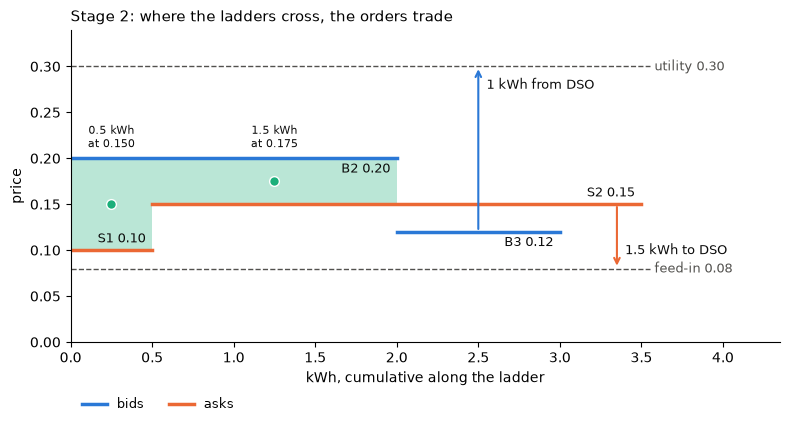

In [8]:
BID_COLOR, ASK_COLOR, TRADE_COLOR = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED = "#0b0b0b", "#52514e"


def ladders(orders):
    # Bids high to low, asks low to high. Ties would go by reputation, then arrival;
    # nobody ties here.
    bids = sorted([o for o in orders if o.is_buy], key=lambda o: -o.price)
    asks = sorted([o for o in orders if not o.is_buy], key=lambda o: o.price)
    return bids, asks


def draw_ladder(ax, ladder, color, label_offset, remaining):
    # One step per order, with its name, and an arrow for what stage 2 left open.
    x = 0.0
    for o in ladder:
        ax.plot([x, x + o.quantity], [o.price, o.price], color=color, linewidth=2.5)
        ax.text(x + o.quantity - 0.04, o.price + label_offset, f"{o.agent_id} {o.price:.2f}",
                color=INK, fontsize=9, ha="right", va="center")
        x += o.quantity

        if o.agent_id in remaining:    # traded from the left, so the rest is on the right
            rest = remaining[o.agent_id]
            if o.is_buy:
                arrow_x, target, text_y, text = x - rest / 2, UTILITY, UTILITY - 0.02, "from DSO"
            else:
                arrow_x, target, text_y, text = x - 0.15, FIT, FIT + 0.02, "to DSO"
            ax.annotate("", xy=(arrow_x, target), xytext=(arrow_x, o.price),
                        arrowprops=dict(arrowstyle="->", color=color, linewidth=1.5))
            ax.text(arrow_x + 0.05, text_y, f"{rest:g} kWh {text}", color=INK, fontsize=9, va="center")


def draw_book(ax, orders, stage_2, title):
    bids, asks = ladders(orders)

    open_kwh = {}
    for o in stage_2.remaining:
        open_kwh[o.agent_id] = o.quantity

    prices = {}
    for o in orders:
        prices[o.agent_id] = o.price

    # The tariffs the DSO clears the rest at
    width = max(sum(o.quantity for o in bids), sum(o.quantity for o in asks))
    for tariff, name in ((UTILITY, "utility"), (FIT, "feed-in")):
        ax.plot([0, width + 0.05], [tariff, tariff], color=MUTED, linewidth=1, linestyle="--")
        ax.text(width + 0.08, tariff, f"{name} {tariff:.2f}", color=MUTED, fontsize=9, va="center")

    # One block per stage 2 trade, left to right
    x = 0.0
    for t in stage_2.trades:
        ask, bid = prices[t.seller_id], prices[t.buyer_id]
        ax.fill_between([x, x + t.quantity], ask, bid, color=TRADE_COLOR, alpha=0.3, linewidth=0)
        middle = x + t.quantity / 2
        ax.plot(middle, t.price, "o", color=TRADE_COLOR, markersize=7, markeredgecolor="white")
        ax.text(middle, bid + 0.008, f"{t.quantity:g} kWh\nat {t.price:.3f}",
                color=INK, fontsize=8, ha="center", va="bottom")
        x += t.quantity

    draw_ladder(ax, bids, BID_COLOR, -0.012, open_kwh)
    draw_ladder(ax, asks, ASK_COLOR, 0.012, open_kwh)

    ax.plot([], [], color=BID_COLOR, linewidth=2.5, label="bids")
    ax.plot([], [], color=ASK_COLOR, linewidth=2.5, label="asks")
    ax.legend(loc="upper left", bbox_to_anchor=(0, -0.14), ncol=2, frameon=False, fontsize=9)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel("kWh, cumulative along the ladder")
    ax.set_ylabel("price")
    ax.set_xlim(0, width + 0.85)
    ax.set_ylim(0, 0.34)
    ax.spines[["top", "right"]].set_visible(False)


def trades_table(stage_2, orders):
    prices = {}
    for o in orders:
        prices[o.agent_id] = o.price

    rows = []
    for t in stage_2.trades:
        rows.append({
            "seller": t.seller_id,
            "buyer": t.buyer_id,
            "ask": prices[t.seller_id],
            "bid": prices[t.buyer_id],
            "kWh": t.quantity,
            "price": t.price,
            "seller gains over FiT": t.price - FIT,
            "buyer saves over utility": UTILITY - t.price,
        })
    return pd.DataFrame(rows)


def why_it_stopped(stage_2):
    bids, asks = ladders(stage_2.remaining)
    if bids and asks:
        print(f"Stopped: best open bid {bids[0].agent_id} {bids[0].price:.2f} < "
              f"best open ask {asks[0].agent_id} {asks[0].price:.2f}")
    elif bids or asks:
        print("Stopped: only one side is left")
    else:
        print("Stopped: nothing is left")


# The real stages, on the orders stage 1 left open
book_crossing = after_stage_1.remaining
stage_2_crossing = clearing.double_auction(book_crossing)
stage_3_crossing = clearing.dso(stage_2_crossing.remaining)

display(trades_table(stage_2_crossing, book_crossing))
why_it_stopped(stage_2_crossing)

fig, ax = plt.subplots(figsize=(8, 4.4))
draw_book(ax, book_crossing, stage_2_crossing, "Stage 2: where the ladders cross, the orders trade")
plt.tight_layout()
plt.show()

### What the auction changes: when the bids do not cross

Now the same orders with one change: both sellers ask 0.21 instead of 0.10 and
0.15. The best bid is 0.20, so the ladders miss each other by 0.01 and stage 2 makes
no trade. Every order goes to the DSO: the sellers get 0.08 and the buyers pay 0.30,
although any price between the two would have been better for both sides.

That is the auction's whole effect on the outcome here. The DSO buys at
$p_\text{FiT}$ and sells at $p_\text{utility}$, so each kWh that goes through it
leaves a margin of $p_\text{utility} - p_\text{FiT} = 0.22$. Each kWh matched in
stage 2 hands that margin to the pair, since

$$
(p - p_\text{FiT}) + (p_\text{utility} - p) = p_\text{utility} - p_\text{FiT}
$$

for any price $p$. The bid and the ask decide **whether** a pair trades and how
the 0.22 is split between them, not how large it is. Fees are left out here.


Stopped: best open bid B2 0.20 < best open ask S1 0.21


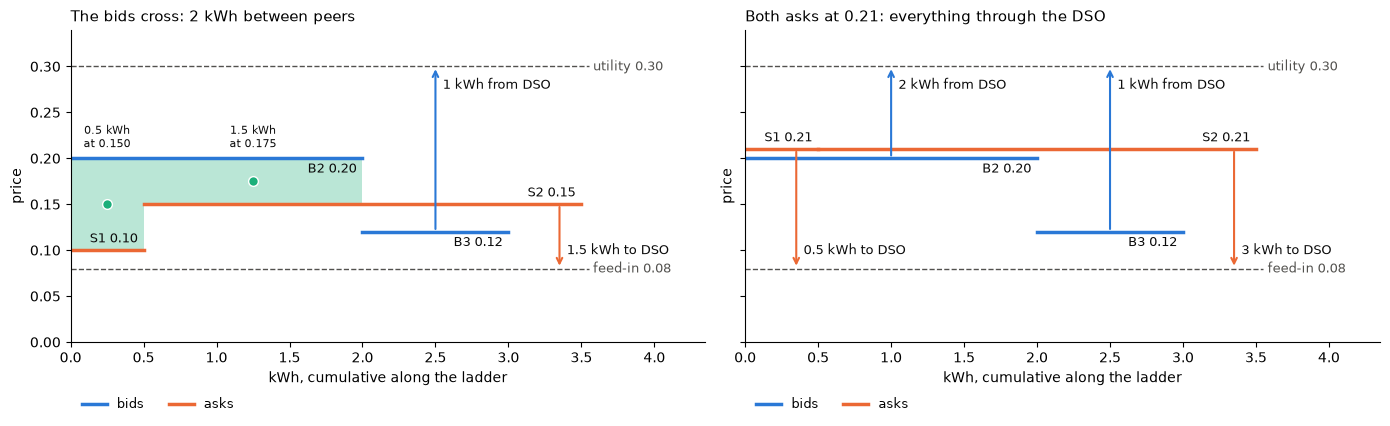

The DSO keeps 0.44 more without the auction's trades: 2 kWh x 0.22


by hand    code match
case              quantity                             
the bids cross    peer kWh         2.0000  2.0000   yes
                  DSO bought kWh   1.5000  1.5000   yes
                  DSO sold kWh     1.0000  1.0000   yes
                  sellers get      0.4575  0.4575   yes
                  buyers pay       0.6375  0.6375   yes
                  DSO keeps        0.1800  0.1800   yes
both asks at 0.21 peer kWh         0.0000  0.0000   yes
                  DSO bought kWh   3.5000  3.5000   yes
                  DSO sold kWh     3.0000  3.0000   yes
                  sellers get      0.2800  0.2800   yes
                  buyers pay       0.9000  0.9000   yes
                  DSO keeps        0.6200  0.6200   yes

In [9]:
# One change: both sellers ask 0.21
book_apart = []
for o in book_crossing:
    if o.is_buy:
        book_apart.append(o)
    else:
        book_apart.append(replace(o, price=0.21))

stage_2_apart = clearing.double_auction(book_apart)
stage_3_apart = clearing.dso(stage_2_apart.remaining)
why_it_stopped(stage_2_apart)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), sharey=True)
draw_book(axes[0], book_crossing, stage_2_crossing, "The bids cross: 2 kWh between peers")
draw_book(axes[1], book_apart, stage_2_apart, "Both asks at 0.21: everything through the DSO")
plt.tight_layout()
plt.show()


def money(stage_2, stage_3):
    # Who gets what over stages 2 and 3, fees aside
    peer_kwh, dso_bought, dso_sold = 0.0, 0.0, 0.0
    sellers_get, buyers_pay, dso_keeps = 0.0, 0.0, 0.0

    for t in stage_2.trades + stage_3.trades:
        value = t.price * t.quantity
        if t.buyer_id == DSO_ID:
            dso_bought += t.quantity
            dso_keeps -= value
            sellers_get += value
        elif t.seller_id == DSO_ID:
            dso_sold += t.quantity
            dso_keeps += value
            buyers_pay += value
        else:
            peer_kwh += t.quantity
            sellers_get += value
            buyers_pay += value

    return {"peer kWh": peer_kwh, "DSO bought kWh": dso_bought, "DSO sold kWh": dso_sold,
            "sellers get": sellers_get, "buyers pay": buyers_pay, "DSO keeps": dso_keeps}


# By hand, the bids cross: 2 kWh between peers, S2's 1.5 and B3's 1.0 with the DSO
hand_crossing = {
    "peer kWh": 0.5 + 1.5,
    "DSO bought kWh": 1.5,
    "DSO sold kWh": 1.0,
    "sellers get": 0.5 * 0.15 + 1.5 * 0.175 + 1.5 * FIT,
    "buyers pay": 0.5 * 0.15 + 1.5 * 0.175 + 1.0 * UTILITY,
    "DSO keeps": 1.0 * UTILITY - 1.5 * FIT,
}

# By hand, the bids do not cross: all 3.5 kWh sold and all 3.0 kWh bought with the DSO
hand_apart = {
    "peer kWh": 0.0,
    "DSO bought kWh": 3.5,
    "DSO sold kWh": 3.0,
    "sellers get": 3.5 * FIT,
    "buyers pay": 3.0 * UTILITY,
    "DSO keeps": 3.0 * UTILITY - 3.5 * FIT,
}

code_crossing = money(stage_2_crossing, stage_3_crossing)
code_apart = money(stage_2_apart, stage_3_apart)

tables = {
    "the bids cross": compare("6 double auction, the bids cross", hand_crossing, code_crossing),
    "both asks at 0.21": compare("6 double auction, no crossing", hand_apart, code_apart),
}

margin_moved = code_apart["DSO keeps"] - code_crossing["DSO keeps"]
print(f"The DSO keeps {margin_moved:.2f} more without the auction's trades: "
      f"{code_crossing['peer kWh']:g} kWh x {UTILITY - FIT:.2f}")

pd.concat(tables, names=["case"])

## 7. Settlement (eq. 13, 14, 16)

**Rule** ([phase 4](../../docs/methodology/market/step.md#4-settlement)). After its trades a
participant has

$$
B = (G - D) + (\text{bought} - \text{sold})
$$

left at its bus (eq. 13). A surplus charges the battery and a deficit discharges
it (eq. 16, section 3); what the battery cannot take or give is exchanged with
the upstream grid untraded: $\text{external} = B - \text{charge} + \text{discharge}$
(an untraded import is *deferred demand*). The step's profit before fees is
$\sum p\,q_\text{sold} - \sum p\,q_\text{bought}$ (eq. 14).

Four cases. A, B and C have $G = 4$, $D = 1$ and a 10 kWh battery at 5 kWh (no
power limit); D has $G = 1$, $D = 4$ and no battery. MP-1a (the battery as a
passive buffer) and MP-1b (the untraded energy's price) are the open decisions
here.

In [10]:
SETTLE = {  # case: (G, D, battery?, sold kWh, bought kWh, price)
    "A sells its surplus": (4.0, 1.0, True, 3.0, 0.0, 0.15),
    "B sells beyond it": (4.0, 1.0, True, 5.0, 0.0, 0.15),
    "C sells less": (4.0, 1.0, True, 1.0, 0.0, 0.15),
    "D buys too little": (1.0, 4.0, False, 0.0, 1.0, 0.20),
}


def by_hand(G, D, battery, sold, bought, price):
    # eq. 13: what is left at the bus after the trades
    B = (G - D) + (bought - sold)

    # eq. 16: a surplus charges the battery, a deficit discharges it, each up to
    # the battery's room (E = 5 kWh, E_max = 9, E_min = 1, efficiency 0.95)
    charge, discharge = 0.0, 0.0
    if battery and B > 0:
        charge = min(B, (9 - 5) / 0.95)
    if battery and B < 0:
        discharge = min(-B, (5 - 1) * 0.95)

    if battery:
        E_after = 5 + charge * 0.95 - discharge / 0.95
    else:
        E_after = None

    # What the battery could not take or give goes to the upstream grid, untraded
    external = B - charge + discharge
    deferred_demand = max(0.0, -external)   # an untraded import

    profit = price * sold - price * bought   # eq. 14

    return {"B": B, "charge": charge, "discharge": discharge, "external": external,
            "deferred demand": deferred_demand, "E after": E_after, "profit": profit}


def by_code(G, D, battery, sold, bought, price):
    if battery:
        b = Battery(BATTERY, step_hours=1.0)
    else:
        b = None
    me = Participant("A", "bus", [], [G], [D], b)

    # Trade(buyer, seller, price, kWh, time): A on the seller or the buyer side
    trades = []
    if sold:
        trades.append(Trade("X", "A", price, sold, 0.0))
    if bought:
        trades.append(Trade("A", "X", price, bought, 0.0))

    o = me.settle(0, trades)
    return {"B": o.balance_kwh, "charge": o.charge_kwh, "discharge": o.discharge_kwh,
            "external": o.external_kwh, "deferred demand": o.deferred_demand_kwh,
            "E after": o.soc_kwh, "profit": o.profit}


tables = {}
for case, values in SETTLE.items():
    hand = by_hand(*values)
    code = by_code(*values)
    tables[case] = compare(f"7 settlement, {case}", hand, code)

pd.concat(tables, names=["case"])

by hand      code match
case                quantity                                 
A sells its surplus B                0.000000  0.000000   yes
                    charge           0.000000  0.000000   yes
                    discharge        0.000000  0.000000   yes
                    external         0.000000  0.000000   yes
                    deferred demand  0.000000  0.000000   yes
                    E after          5.000000  5.000000   yes
                    profit           0.450000  0.450000   yes
B sells beyond it   B               -2.000000 -2.000000   yes
                    charge           0.000000  0.000000   yes
                    discharge        2.000000  2.000000   yes
                    external         0.000000  0.000000   yes
                    deferred demand  0.000000  0.000000   yes
                    E after          2.894737  2.894737   yes
                    profit           0.750000  0.750000   yes
C sells less        B                2.000000  2.000000   yes
                    charge           2.000000  2.000000   yes
                    discharge        0.000000  0.000000   yes
                    external         0.000000  0.000000   yes
                    deferred demand  0.000000  0.000000   yes
                    E after          6.900000  6.900000   yes
                    profit           0.150000  0.150000   yes
D buys too little   B               -2.000000 -2.000000   yes
                    charge           0.000000  0.000000   yes
                    discharge        0.000000  0.000000   yes
                    external        -2.000000 -2.000000   yes
                    deferred demand  2.000000  2.000000   yes
                    E after               NaN       NaN   yes
                    profit          -0.200000 -0.200000   yes

## 8. A participant's power at its bus

**Rule** ([phase 5](../../docs/methodology/market/step.md#5-grid)). The power flow sees what
the participant physically did, never its trades: production
$(G + \text{discharge})/\Delta t$, consumption $(D + \text{charge})/\Delta t$,
net injection the difference. Case B of section 7: it sold 5 kWh with a surplus
of 3, so the battery gave 2.

In [11]:
# Case B of section 7: G = 4, D = 1, sold 5 kWh, so the battery discharged 2 kWh
b = Battery(BATTERY, step_hours=1.0)
me = Participant("A", "bus 7", [], [4.0], [1.0], b)
outcome = me.settle(0, [Trade("X", "A", 0.15, 5.0, 0.0)])
inj = me.injection(outcome, 1.0)   # 1-hour step

# By hand
G, D, charge, discharge, step_h = 4.0, 1.0, 0.0, 2.0, 1.0
production = (G + discharge) / step_h     # 6 kW
consumption = (D + charge) / step_h       # 1 kW

hand = {
    "production kW": production,
    "consumption kW": consumption,
    "net injection kW": production - consumption,
    "bus": "bus 7",
}
code = {
    "production kW": inj.production_kw,
    "consumption kW": inj.consumption_kw,
    "net injection kW": inj.net_injection_kw,
    "bus": inj.bus_id,
}

compare("8 injection", hand, code)

,by hand,code,match
quantity,,,
production kW,6.0,6.0,yes
consumption kW,1.0,1.0,yes
net injection kW,5.0,5.0,yes
bus,bus 7,bus 7,yes


## 9. The graph model's line loading

**Rule** ([phase 5](../../docs/methodology/market/step.md#5-grid), [P1] §3.5.3, eq. 19;
`grid.method = "graph"`). Each line gets a capacity: `"paper"` spreads a total
$C_\text{tot}$ over the lines in inverse proportion to their length,
$C_e = C_\text{tot}\,(1/\ell_e) / \sum_k (1/\ell_k)$; `"ratings"` uses each
line's rating. Every trade adds its power to each line of its path; the loading is
$100 \cdot \text{flow}/C_e$ percent.

Three lines of 0.1, 0.2 and 0.4 km, each rated 100 kW. Trade X runs over L1 and
L2 at 20 kW, trade Y over L2 and L3 at 10 kW.

In [12]:
LINES = {"L1": (0.1, 100.0), "L2": (0.2, 100.0), "L3": (0.4, 100.0)}   # line: (km, rating kW)
FLOWS = [
    (GridPath(lines=("L1", "L2")), 20.0),   # trade X
    (GridPath(lines=("L2", "L3")), 10.0),   # trade Y
]

# By hand, "paper" capacities: C_tot = the sum of the ratings = 300 kW,
# spread in proportion to 1/length = 10, 5 and 2.5 (sum 17.5)
cap = {
    "L1": 300 * 10 / 17.5,    # 171.4 kW
    "L2": 300 * 5 / 17.5,     # 85.7 kW
    "L3": 300 * 2.5 / 17.5,   # 42.9 kW
}
# The flow on each line: the trades whose path uses it
flow = {
    "L1": 20.0,          # X
    "L2": 20.0 + 10.0,   # X and Y
    "L3": 10.0,          # Y
}

hand = {}
for line in LINES:
    hand[f"capacity {line}"] = cap[line]
for line in LINES:
    hand[f"loading {line} %"] = round(100 * flow[line] / cap[line], 2)
for line in LINES:
    rating = LINES[line][1]
    hand[f"loading {line} %, ratings"] = round(100 * flow[line] / rating, 2)

# The code
paper_capacity = capacities(LINES, "paper")
paper_loading = GraphGrid(LINES, "paper").assess(0, FLOWS).line_loading_percent
rated_loading = GraphGrid(LINES, "ratings").assess(0, FLOWS).line_loading_percent

code = {}
for line in LINES:
    code[f"capacity {line}"] = paper_capacity[line]
for line in LINES:
    code[f"loading {line} %"] = paper_loading[line]
for line in LINES:
    code[f"loading {line} %, ratings"] = rated_loading[line]

compare("9 graph model", hand, code)

,by hand,code,match
quantity,,,
capacity L1,171.428571,171.428571,yes
capacity L2,85.714286,85.714286,yes
capacity L3,42.857143,42.857143,yes
loading L1 %,11.670000,11.670000,yes
loading L2 %,35.000000,35.000000,yes
loading L3 %,23.330000,23.330000,yes
"loading L1 %, ratings",20.000000,20.000000,yes
"loading L2 %, ratings",30.000000,30.000000,yes
"loading L3 %, ratings",10.000000,10.000000,yes


## 10. The grid fee of a peer trade (eq. 8)

**Rule** ([phase 6](../../docs/methodology/market/step.md#6-fees), [P1] eq. 8a-8g). With
$v = q\,p$ the trade's value and $C_t$ the highest loading on its path (0 to 1):

$$
\begin{aligned}
F_\text{cong} &= f_\text{cong}\,(C_t - C_\text{th})\,v \ \text{ if } C_t > C_\text{th} \\
F_\text{thermal} &= \min\bigl(\tfrac{C_t - T_\text{th}}{1 - T_\text{th}},\ f_\text{threshold}\bigr)\,v \ \text{ if } C_t > T_\text{th} \\
F_\text{volt} &= \min(f_\text{volt}\,d,\ V_\text{th})\,v \\
F_\text{trans} &= l\,p, \quad l = d\,q\,\kappa \ \text{(eq. 18)} \\
F_\text{zone} &= -f_\text{zone}\,v \ \text{ if both ends on one feeder}
\end{aligned}
$$

The buyer pays `fee_buyer_share` (0.5) of the total, the seller the rest. The
factors are the reference scenario's (`DsoSetup`'s defaults): $f_\text{cong} =
0.5$, $C_\text{th} = 0.8$, $T_\text{th} = 0.2$, $f_\text{threshold} = 0.3$,
$f_\text{volt} = 0.15$/km, $V_\text{th} = 0.05$, $\kappa = 0.03$/km, $f_\text{zone}
= 0.15$. The numbers below make every part non-zero: 2 kWh at 0.20 over 0.5 km,
lines loaded 95 % and 50 %, one feeder. Open decisions here: MP-4a to MP-4f.

In [13]:
Q, P, KM_PATH = 2.0, 0.20, 0.5            # kWh, price, path length km
LOADING = {"L1": 95.0, "L2": 50.0}        # the path's lines, % loaded
f = DsoSetup()                            # the reference scenario's fee factors

# By hand
v = Q * P                                    # the trade's value: 0.40
C = min(1.0, max(LOADING.values()) / 100)    # the highest loading on the path: 0.95
loss = KM_PATH * Q * f.loss_factor           # eq. 18: 0.5 km x 2 kWh x 0.03

if C > f.congestion_threshold:               # 0.95 > 0.8
    congestion = f.congestion_factor * (C - f.congestion_threshold) * v
else:
    congestion = 0.0

if C > f.thermal_threshold:                  # 0.95 > 0.2
    thermal_share = (C - f.thermal_threshold) / (1 - f.thermal_threshold)
    thermal = min(thermal_share, f.thermal_cap) * v
else:
    thermal = 0.0

voltage = min(f.voltage_factor * KM_PATH, f.voltage_threshold) * v
transmission = loss * P
zone = -f.zone_factor * v                    # both ends on feeder 1: a bonus
imbalance = 0.0                              # only DSO trades (section 11)

total = congestion + thermal + voltage + transmission + zone + imbalance

hand = {
    "loss kWh": loss,
    "congestion": congestion,
    "thermal": thermal,
    "voltage": voltage,
    "transmission": transmission,
    "zone": zone,
    "imbalance": imbalance,
    "total": total,
    "buyer pays": total * f.fee_buyer_share,
    "seller pays": total * (1 - f.fee_buyer_share),
}

# The code: the DSO sees the loading (as after the step's power flow), assesses the
# trade as it clears (distance, loss), then charges it.
dso = Dso(f)
dso.observe(SimpleNamespace(line_loading_percent=LOADING, bus_voltage_pu={}))
path = GridPath(KM_PATH, ("L1", "L2"), "feeder 1", "feeder 1", "bus S", "bus B")
trade = dso.assess(Trade("B", "S", P, Q, 0.0), path)
peer_path = lambda seller, buyer: path       # every peer trade runs over this path
dso_path = lambda participant: GridPath()    # no DSO trades here
[charged] = dso.charge([trade], peer_path, dso_path)

parts = charged.fee_parts
code = {
    "loss kWh": charged.transmission_loss,
    "congestion": parts.congestion,
    "thermal": parts.thermal,
    "voltage": parts.voltage,
    "transmission": parts.transmission,
    "zone": parts.zone,
    "imbalance": parts.imbalance,
    "total": charged.fees,
    "buyer pays": charged.buyer_fee,
    "seller pays": charged.seller_fee,
}

compare("10 peer fee (eq. 8)", hand, code)

,by hand,code,match
quantity,,,
loss kWh,0.030,0.030,yes
congestion,0.030,0.030,yes
thermal,0.120,0.120,yes
voltage,0.020,0.020,yes
transmission,0.006,0.006,yes
zone,-0.060,-0.060,yes
imbalance,0.000,0.000,yes
total,0.116,0.116,yes
buyer pays,0.058,0.058,yes


## 11. The fee of a trade with the DSO (eq. 8b, 8h)

**Rule** ([phase 6](../../docs/methodology/market/step.md#6-fees)). A DSO trade runs along
the participant's path to the transformer and gets the same parts as section 10,
without the zone bonus, plus the imbalance fee: when the trade **worsens** the
market's balance $B_\text{grid}$ (offered minus asked before stage 3; the DSO
buys during excess demand, or sells during excess supply),

$$
F_\text{imb} = f_\text{imb}\,\min\bigl(q / |B_\text{grid}|,\ 1\bigr)\,v,
\qquad f_\text{imb} = 0.15 .
$$

A trade that helps pays no imbalance fee. The participant pays the whole fee.

The DSO sells 1 kWh at 0.30 over 0.2 km of line L1 (95 % loaded), once with
excess supply ($B_\text{grid} = +4$: it worsens) and once with excess demand
($B_\text{grid} = -4$: it helps). Open decision: MP-4b (M-30, which DSO trade
helps the balance).

In [14]:
Q, P, KM_UP = 1.0, 0.30, 0.2   # the DSO sells 1 kWh at 0.30, 0.2 km up to the transformer


def hand_dso_fee(balance):
    v = Q * P             # 0.30
    C = 0.95              # L1's loading
    loss = KM_UP * Q * f.loss_factor

    # The DSO sells. Selling into excess supply (B_grid > 0) worsens the balance.
    dso_sells = True
    worsens = dso_sells and balance > 0

    congestion = f.congestion_factor * (C - f.congestion_threshold) * v
    thermal = min((C - f.thermal_threshold) / (1 - f.thermal_threshold), f.thermal_cap) * v
    voltage = min(f.voltage_factor * KM_UP, f.voltage_threshold) * v
    transmission = loss * P
    zone = 0.0                     # no zone bonus with the DSO
    if worsens:
        imbalance = f.imbalance_factor * min(Q / abs(balance), 1) * v
    else:
        imbalance = 0.0

    total = congestion + thermal + voltage + transmission + zone + imbalance
    return {"congestion": congestion, "thermal": thermal, "voltage": voltage,
            "transmission": transmission, "zone": zone, "imbalance": imbalance,
            "total": total,
            "buyer pays": total,   # the participant pays the whole fee
            "seller pays": 0.0}    # the DSO pays nothing


def code_dso_fee(balance):
    dso = Dso(f)
    dso.observe(SimpleNamespace(line_loading_percent={"L1": 95.0}, bus_voltage_pu={}))
    up = GridPath(KM_UP, ("L1",), "feeder 1", "feeder 1", "bus P", "transformer")
    trade = dso.assess(Trade("P", DSO_ID, P, Q, 0.0, stage=3), up)
    peer_path = lambda seller, buyer: GridPath()   # no peer trades here
    dso_path = lambda participant: up
    [c] = dso.charge([trade], peer_path, dso_path, grid_balance_kwh=balance)

    parts = c.fee_parts
    return {"congestion": parts.congestion, "thermal": parts.thermal,
            "voltage": parts.voltage, "transmission": parts.transmission,
            "zone": parts.zone, "imbalance": parts.imbalance,
            "total": c.fees, "buyer pays": c.buyer_fee, "seller pays": c.seller_fee}


tables = {}
for balance in (4.0, -4.0):
    name = f"B_grid {balance:+}"
    tables[name] = compare(f"11 DSO fee, {name}", hand_dso_fee(balance), code_dso_fee(balance))

pd.concat(tables, names=["case"])

by hand     code match
case        quantity                            
B_grid +4.0 congestion    0.02250  0.02250   yes
            thermal       0.09000  0.09000   yes
            voltage       0.00900  0.00900   yes
            transmission  0.00180  0.00180   yes
            zone          0.00000  0.00000   yes
            imbalance     0.01125  0.01125   yes
            total         0.13455  0.13455   yes
            buyer pays    0.13455  0.13455   yes
            seller pays   0.00000  0.00000   yes
B_grid -4.0 congestion    0.02250  0.02250   yes
            thermal       0.09000  0.09000   yes
            voltage       0.00900  0.00900   yes
            transmission  0.00180  0.00180   yes
            zone          0.00000  0.00000   yes
            imbalance     0.00000  0.00000   yes
            total         0.12330  0.12330   yes
            buyer pays    0.12330  0.12330   yes
            seller pays   0.00000  0.00000   yes

## 12. Paying the fees

**Rule** ([phase 6](../../docs/methodology/market/step.md#6-fees), 6c). A participant pays its
share of every trade it is in (`buyer_fee` as buyer, `seller_fee` as seller); it
comes off the step's profit and the running profit. Case A of section 7 (sold 3
kWh at 0.15 for 0.45), with that trade charged a fee of 0.02, split 50/50.

In [15]:
# Case A of section 7: sold 3 kWh at 0.15; the trade's fee 0.02 is split 50/50
b = Battery(BATTERY, step_hours=1.0)
me = Participant("A", "bus", [], [4.0], [1.0], b)
trade = Trade("X", "A", 0.15, 3.0, 0.0, fees=0.02, buyer_fee=0.01, seller_fee=0.01)
settled = me.settle(0, [trade])
outcome = me.pay_fees(settled, [trade])

# By hand: A is the seller, so it pays seller_fee
fee = 0.01
revenue = 0.15 * 3
hand = {
    "fees": fee,
    "step profit": revenue - fee,
    "running profit": revenue - fee,   # the first step, so the same
}
code = {
    "fees": outcome.fees,
    "step profit": outcome.profit,
    "running profit": me.profit,
}

compare("12 paying the fees", hand, code)

,by hand,code,match
quantity,,,
fees,0.01,0.01,yes
step profit,0.44,0.44,yes
running profit,0.44,0.44,yes


## 13. The DSO's step (eq. 7)

**Rule** ([phase 7](../../docs/methodology/market/step.md#7-record), [P1] eq. 7). The DSO's
balance is what it sold minus what it bought, $B_\text{DSO} = \sum (E_\text{sold}
- E_\text{bought})$; its energy revenue is what it was paid minus what it paid;
it also collects the fees. Stage 3 of section 6: it bought 1.5 kWh from S2 at
0.08 and sold 1.0 kWh to B3 at 0.30 (no fees charged there).

In [16]:
# By hand: section 6's stage 3, bought 1.5 kWh at 0.08 from S2, sold 1.0 kWh at 0.30 to B3
bought, sold = 1.5, 1.0
hand = {
    "bought kWh": bought,
    "sold kWh": sold,
    "balance kWh": sold - bought,             # eq. 7
    "energy revenue": sold * 0.30 - bought * 0.08,
    "fees": 0.0,                              # no fees charged in section 6
}

# The code: the DSO settles section 6's stage 3 trades
out = Dso(DsoSetup(prices={"utility": UTILITY, "feed_in": FIT})).settle(after_stage_3.trades)
code = {
    "bought kWh": out.bought_kwh,
    "sold kWh": out.sold_kwh,
    "balance kWh": out.balance_kwh,
    "energy revenue": out.energy_revenue,
    "fees": out.fees,
}

compare("13 DSO balance (eq. 7)", hand, code)

,by hand,code,match
quantity,,,
bought kWh,1.50,1.50,yes
sold kWh,1.00,1.00,yes
balance kWh,-0.50,-0.50,yes
energy revenue,0.18,0.18,yes
fees,0.00,0.00,yes


## 14. Reputation (eq. 12)

**Rule** ([phase 8](../../docs/methodology/market/step.md#8-reputation-and-advance), [P1]
eq. 12, §3.3.4). Each step, a participant with trades gets three components, each
0 to 1:

- **reliability**: the share of its order volume that *peers* matched;
- **fairness**: $1 - $ the mean of $|p - p_\text{clear}|/p_\text{clear}$ over its
  peer trades;
- **grid**: per trade $\pm\min(q/|B_\text{grid}|, 1)$, $+$ when it helps the
  balance (buying during excess supply, selling during excess demand), 0 for a DSO
  trade; the mean, mapped from $[-1, 1]$ to $[0, 1]$.

The score is $0.3\,\text{rel} + 0.2\,\text{fair} + 0.5\,\text{grid}$ and the
reputation $r \leftarrow \text{decay}\cdot r + (1 - \text{decay})\cdot\text{score}$
with decay 0.8 per hour. Open: MP-5a, MP-5b (does one day give reputation time to
mean anything).

Participant A (reputation 0.5) offered 2 kWh: 1.5 went to peer B at 0.18, 0.5 to
the DSO. The step's clearing price was 0.20, with excess supply $B_\text{grid} =
+3$.

In [17]:
# A offered 2 kWh; 1.5 went to peer B at 0.18 (stage 2), 0.5 to the DSO (stage 3)
order = Order("a", "A", 0.15, 2.0, False, 0.0)
trades = [
    Trade("B", "A", 0.18, 1.5, 0.0, stage=2),
    Trade(DSO_ID, "A", 0.08, 0.5, 0.0, stage=3),
]
# The parts of the step's record that reputation reads
record = SimpleNamespace(trades=trades, orders=[order], clearing_price=0.20, grid_balance_kwh=3.0)
agent = SimpleNamespace(id="A", reputation=0.5)

# By hand
reliability = 1.5 / 2.0                    # peers matched 1.5 of its 2 kWh
fairness = 1 - abs(0.18 - 0.20) / 0.20     # its one peer trade, 10 % below the clearing price

grid_peer = -min(1.5 / 3.0, 1)             # sells into excess supply: it worsens (-)
grid_dso = 0.0                             # a DSO trade counts 0
grid_mean = (grid_peer + grid_dso) / 2     # -0.25
grid = (grid_mean + 1) / 2                 # from [-1, 1] to [0, 1]

score = 0.3 * reliability + 0.2 * fairness + 0.5 * grid
reputation = 0.8 * 0.5 + (1 - 0.8) * score  # decay 0.8 on the old 0.5

hand = {
    "reliability": reliability,
    "fairness": fairness,
    "grid": grid,
    "score": score,
    "reputation": reputation,
}

# The code: weights (reliability, fairness, grid) and the decay
u = ReputationHandler(0.3, 0.2, 0.5, decay=0.8).update_reputation(agent, record)
code = {
    "reliability": u.reliability,
    "fairness": u.fairness,
    "grid": u.grid,
    "score": u.score,
    "reputation": u.reputation,
}

compare("14 reputation (eq. 12)", hand, code)

,by hand,code,match
quantity,,,
reliability,0.7500,0.7500,yes
fairness,0.9000,0.9000,yes
grid,0.3750,0.3750,yes
score,0.5925,0.5925,yes
reputation,0.5185,0.5185,yes


## Summary

Every section, PASS when each of its quantities matches. A FAIL means the code
and the rule above disagree: either the code or the rule (the expectation) is
wrong, and the section's table shows which quantity.

In [18]:
summary = pd.DataFrame({"result": RESULTS}).rename_axis("section")
print(f"{(summary.result == 'PASS').sum()} of {len(summary)} sections pass")
summary

20 of 20 sections pass


,result
section,
1 tariffs,PASS
2 order bounds (eq. 15),PASS
3 battery (eq. 16),PASS
4 partner choice,PASS
5 prices,PASS
6 clearing stages,PASS
"6 double auction, the bids cross",PASS
"6 double auction, no crossing",PASS
"7 settlement, A sells its surplus",PASS
